Idea: Use exact r_c values for the 3 different types of fake from correction.ipynb, to see if we get to the exact closure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def calc_hist(vals, bins=10, weights=None, density=False):
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
def getRcAndErr(df, ob):
    nos = sum(df[df.b_ch==-1]['w'])
    nss = sum(df[df.b_ch==+1]['w'])
    rc = (nss-nos)/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    for i in range(0, len(w_array)):
        p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [4]:
def find_p_from_rc(rc):
    p = 0.5*(rc + 1)
    return p

In [5]:
df = pd.read_csv('embed_central.csv')
df

,runnumber,eventnumber,centrality,rho,jet_pt,jet_eta,jet_phi,jet_area,jet_neutral_fraction,jet_leading_track_pt,jet_leading_track_charge,jet_leading_track_y,jet_leading_track_phi,jet_subleading_track_pt,jet_subleading_track_charge,jet_subleading_track_y,jet_subleading_track_phi,w,jet_pt_sub
0,19118050,972332,15,49.151596,77.516910,-0.166111,1.344416,0.518612,0.316091,14.581533,1,-0.027697,1.381795,9.143879,-1,-0.399065,1.324921,0.000147,52.026290
1,19118050,972332,15,49.151596,71.302025,0.121762,4.514166,0.558505,0.453004,15.579208,1,0.108893,4.497229,8.340286,-1,0.115068,4.558971,0.000147,43.850594
2,19118050,972341,15,44.833080,73.614850,0.152616,4.043150,0.498665,0.241201,20.111698,-1,0.154665,4.032149,13.158230,1,0.181555,4.075732,0.000147,51.258140
3,19118050,972380,13,24.216578,71.959080,-0.150803,1.268587,0.488692,0.317732,10.664819,1,-0.134131,1.246811,9.769902,-1,-0.176550,1.260549,0.000147,60.124630
4,19118050,972380,13,24.216578,70.682620,-0.257443,4.382905,0.528585,0.529385,6.311680,-1,-0.238059,4.236941,5.462812,1,-0.313231,4.327429,0.000147,57.882088
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
423491,19118051,3513938,13,24.104270,32.772957,0.544998,3.633040,0.508639,0.220975,6.082830,1,0.463189,3.653504,4.095303,-1,0.491003,3.530557,52.692284,20.512589
423492,19118051,3525965,12,26.787790,29.604560,-0.504558,2.755284,0.448799,0.632046,2.988089,-1,-0.618385,2.522271,1.981661,-1,-0.463513,2.704560,52.692284,17.582230
423493,19118051,3528881,13,31.105503,33.965755,-0.040682,1.002963,0.568479,0.418209,3.199151,1,-0.249464,1.016033,2.630692,1,0.018365,0.663047,52.692284,16.282942
423494,19118051,3532674,14,35.996290,45.268593,-0.372653,1.299000,0.508639,0.607547,3.079540,1,-0.491450,1.449827,2.232569,-1,-0.639282,1.454578,52.692284,26.959484


In [6]:
df.eval('b_ch = jet_leading_track_charge * jet_subleading_track_charge', inplace=True)

In [7]:
df_array = [ df[(df.jet_pt_sub>20) & (df.jet_pt_sub<25)],\
            df[(df.jet_pt_sub>25) & (df.jet_pt_sub<30)],\
            df[(df.jet_pt_sub>30) & (df.jet_pt_sub<40)] ]

In [8]:
rc_embed_array = []
rc_err_embed_array = []
for i in range(0, len(df_array)):
    rc_embed_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_embed_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

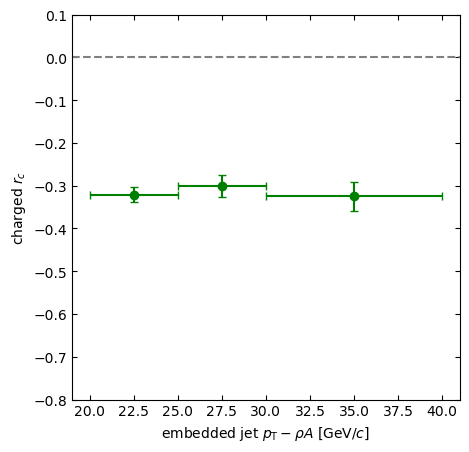

In [9]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_embed_array, ls='none', marker='o', color='g')
plt.errorbar([22.5, 27.5, 35], rc_embed_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_array, capsize=3, ls='none', label='Embedded', color='g')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'embedded jet $p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
#plt.legend(fontsize=12, loc='lower left', frameon=True, framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [10]:
rc_embed_unmatched_array = np.array([-0.08732273837805661, -0.23069981953214125, -0.2841067034634731])

In [11]:
rc_embed_matched_both_unmatched_array = np.array([0.07750314831242171, 0.04138275698107638, 0.38306104427770904])

In [12]:
rc_embed_matched_one_unmatched_array = np.array([-0.04091564497284532, 0.04070514184093624, -0.17584050927203815])

In [13]:
frac_unmatched = np.array([0.01342964984786646, 0.0058870017390103314, 0.008690535862305398])
frac_matched_both_unmatched = np.array([0.033515722230208725, 0.03067454724394646, 0.035922257440589175])
frac_matched_one_unmatched = np.array([0.17062094282608076, 0.18547966140869956, 0.18437676364813027])

In [14]:
rc_corrected_array = []
for i in range(0, len(df_array)):
    rc1 = rc_embed_array[i] - rc_embed_unmatched_array[i]*frac_unmatched[i]
    #print(rc1/(1-frac_unmatched))
    rc2 = rc1 - rc_embed_matched_both_unmatched_array[i]*frac_matched_both_unmatched[i]
    #print(rc2/(1-frac_unmatched-frac_matched_both_unmatched))
    rc3 = rc2 - rc_embed_matched_one_unmatched_array[i]*frac_matched_one_unmatched[i]
    #print(rc3/(1-frac_unmatched-frac_matched_both_unmatched-frac_matched_one_unmatched))
    rc_corrected_array.append(rc3/(1-frac_unmatched[i]-frac_matched_both_unmatched[i]-frac_matched_one_unmatched[i]))

In [15]:
rc_embed_matched_array = np.array([-0.40367041761039746, -0.39549855100828124, -0.3941431221214535])
rc_err_embed_matched_array = np.array([0.01905363048809953, 0.02499385249819641, 0.03175696395765196])

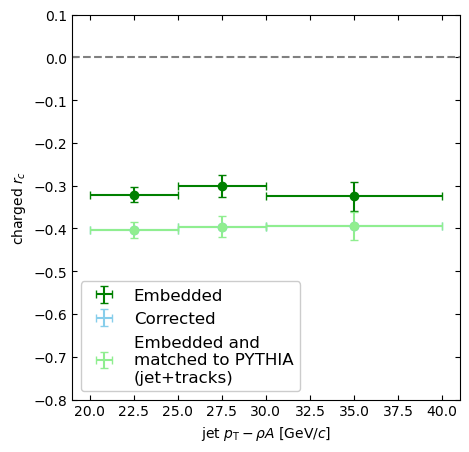

In [16]:
fig=plt.figure(figsize=(5,5))
#plt.errorbar(30, rc_fake, xerr=10, capsize=3, ls='none', color='tab:red', label='Background')
plt.errorbar([22.5, 27.5, 35], rc_embed_array, ls='none', marker='o', color='g')
plt.errorbar([22.5, 27.5, 35], rc_embed_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_array, capsize=3, ls='none', label='Embedded', color='g')
plt.errorbar([22.5, 27.5, 35], rc_corrected_array, ls='none', marker='o', color='skyblue')
plt.errorbar([22.5, 27.5, 35], rc_corrected_array, xerr=[2.5, 2.5, 5], yerr=0, capsize=3, ls='none', label='Corrected', color='skyblue')
plt.errorbar([22.5, 27.5, 35], rc_embed_matched_array, ls='none', marker='o', color='lightgreen')
plt.errorbar([22.5, 27.5, 35], rc_embed_matched_array, xerr=[2.5, 2.5, 5], yerr=rc_err_embed_matched_array, capsize=3, ls='none', label='Embedded and\nmatched to PYTHIA\n(jet+tracks)', color='lightgreen')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel(r'jet $p_{\mathrm{T}}-\rho A$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.8,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=True, framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')

In [17]:
print(rc_corrected_array)

[-0.4036740375483983, -0.3954994891803337, -0.3941586639743229]
